# Modelos y Simulación 2024 — Examen final (16/12/2024)
**Victoria López**

Cada ejercicio tiene su enunciado, la explicación de la resolución y una función `ejercicioN()` que muestra en pantalla las respuestas pedidas.

In [1]:
import math
from random import random

import numpy as np
from scipy import stats

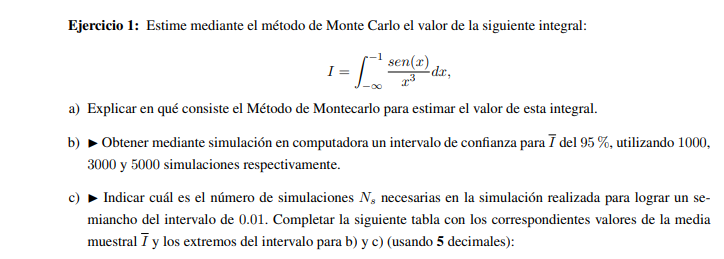

## Ejercicio 1

**Enunciado.** Estime mediante el método de Monte Carlo el valor de la integral

$$I = \int_{-\infty}^{-1} \frac{\operatorname{sen}(x)}{x^3}\,dx$$

a) Explicar en qué consiste el método de Monte Carlo para estimar el valor de esta integral.  
b) ▶ Obtener mediante simulación en computadora un intervalo de confianza para $I$ del 95 %, utilizando 1000, 3000 y 5000 simulaciones respectivamente.  
c) ▶ Indicar cuál es el número de simulaciones $N_s$ necesarias para lograr un semiancho del intervalo de 0.01. Completar la tabla con la media muestral $\bar I$ y los extremos del intervalo para b) y c) (usando 5 decimales).

**a) Resolución.** Con el cambio de variable $x = -1/t$, $dx = dt/t^2$, el intervalo $(-\infty, -1]$ pasa a $(0, 1]$:

$$I = \int_0^1 \frac{\operatorname{sen}(-1/t)}{(-1/t)^3}\,\frac{1}{t^2}\,dt = \int_0^1 t\,\operatorname{sen}(1/t)\,dt = E[g(U)],\quad g(t) = t\,\operatorname{sen}(1/t),\ U\sim U(0,1).$$

Por la ley de los grandes números, $\bar I_n = \frac1n\sum g(U_i) \to I$, y por el TCL el IC del 95 % es $\bar I_n \pm 1.96\,S_n/\sqrt n$.

Para c) se simula hasta que el **semiancho** $1.96\,S_n/\sqrt n$ sea menor que 0.01 (con al menos 100 simulaciones), actualizando media y varianza en forma recursiva.

In [2]:
def g1(t):
    return t * math.sin(1 / t)


def ic_montecarlo(n_sim):
    """Media, desvío muestral e IC 95 % con n_sim simulaciones."""
    valores = [g1(1 - random()) for _ in range(n_sim)]   # 1 - random() en (0, 1]: evita t = 0
    media = sum(valores) / n_sim
    s = math.sqrt(sum((v - media) ** 2 for v in valores) / (n_sim - 1))
    h = 1.96 * s / math.sqrt(n_sim)
    return media, s, (media - h, media + h)


def simular_hasta_semiancho(d, z=1.96):
    """Simula hasta que el semiancho z*S/sqrt(n) sea menor que d (media y varianza recursivas)."""
    media = g1(1 - random())
    s2 = 0.0
    n = 1
    while n < 100 or z * math.sqrt(s2 / n) >= d:
        n += 1
        x = g1(1 - random())
        media_ant = media
        media = media_ant + (x - media_ant) / n
        s2 = (1 - 1 / (n - 1)) * s2 + n * (media - media_ant) ** 2
    h = z * math.sqrt(s2 / n)
    return n, media, (media - h, media + h)


def ejercicio1():
    print("Ejercicio 1")
    print(f"{'N° de sim.':>12} | {'I':>8} | IC(95 %)")
    for n in [1000, 3000, 5000]:
        media, s, (a, b) = ic_montecarlo(n)
        print(f"{n:>12} | {media:.5f} | [{a:.5f}, {b:.5f}]")
    ns, media, (a, b) = simular_hasta_semiancho(0.01)
    print(f"{'Ns = ' + str(ns):>12} | {media:.5f} | [{a:.5f}, {b:.5f}]")
    print(f"\nc) Ns = {ns} simulaciones para un semiancho menor que 0.01")


ejercicio1()

Ejercicio 1
  N° de sim. |        I | IC(95 %)
        1000 | 0.36357 | [0.34121, 0.38593]
        3000 | 0.38513 | [0.37238, 0.39788]
        5000 | 0.37316 | [0.36320, 0.38312]
   Ns = 5007 | 0.37468 | [0.36468, 0.38468]

c) Ns = 5007 simulaciones para un semiancho menor que 0.01


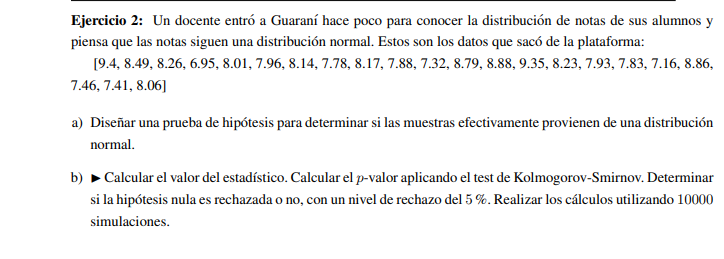

## Ejercicio 2

**Enunciado.** Un docente entró a Guaraní hace poco para conocer la distribución de notas de sus alumnos y piensa que las notas siguen una distribución normal. Estos son los datos que sacó de la plataforma:

`[9.4, 8.49, 8.26, 6.95, 8.01, 7.96, 8.14, 7.78, 8.17, 7.88, 7.32, 8.79, 8.88, 9.35, 8.23, 7.93, 7.83, 7.16, 8.86, 7.46, 7.41, 8.06]`

a) Diseñar una prueba de hipótesis para determinar si las muestras efectivamente provienen de una distribución normal.  
b) ▶ Calcular el valor del estadístico. Calcular el p-valor aplicando el test de Kolmogorov-Smirnov. Determinar si la hipótesis nula es rechazada o no, con un nivel de rechazo del 5 %. Realizar los cálculos utilizando 10000 simulaciones.

**a) Resolución.** $H_0$: las notas provienen de una $N(\mu, \sigma^2)$; $H_1$: no. Como $\mu$ y $\sigma$ no se conocen, se estiman con la media muestral $\bar X$ y el desvío muestral $S$. El estadístico es

$$D = \max_{1\le j\le n} \max\left\{\tfrac jn - F(x_{(j)}),\ F(x_{(j)}) - \tfrac{j-1}n\right\},$$

con $F$ la normal estimada. Como los parámetros se estimaron con los datos, el p-valor se simula así: se generan $n$ normales con $(\bar X, S)$, **se re-estiman** media y desvío con esa muestra, se calcula su $D$ y se cuenta la proporción de veces que $D \ge d$. Se rechaza $H_0$ si el p-valor es menor que 0.05.

In [3]:
NOTAS = [9.4, 8.49, 8.26, 6.95, 8.01, 7.96, 8.14, 7.78, 8.17, 7.88, 7.32,
         8.79, 8.88, 9.35, 8.23, 7.93, 7.83, 7.16, 8.86, 7.46, 7.41, 8.06]


def estadistico_ks_normal(datos):
    x = np.sort(np.asarray(datos))
    n = len(x)
    mu, s = x.mean(), x.std(ddof=1)
    F = stats.norm.cdf(x, loc=mu, scale=s)
    j = np.arange(1, n + 1)
    return max(np.max(j / n - F), np.max(F - (j - 1) / n))


def ejercicio2(n_sim=10_000, alfa=0.05):
    n = len(NOTAS)
    mu = np.mean(NOTAS)
    s = np.std(NOTAS, ddof=1)
    d = estadistico_ks_normal(NOTAS)

    exitos = 0
    for _ in range(n_sim):
        muestra = np.random.normal(mu, s, size=n)
        if estadistico_ks_normal(muestra) >= d:     # re-estima mu y sigma en cada muestra
            exitos += 1
    p_valor = exitos / n_sim

    print("Ejercicio 2")
    print(f"Media estimada = {mu:.4f}, desvío estimado S = {s:.4f}")
    print(f"Estadístico D observado = {d:.4f}")
    print(f"p-valor ({n_sim} simulaciones) = {p_valor:.4f}")
    print("Se rechaza H0" if p_valor < alfa else "No se rechaza H0", "con nivel del 5 %")


ejercicio2()

Ejercicio 2
Media estimada = 8.1055, desvío estimado S = 0.6582
Estadístico D observado = 0.1345
p-valor (10000 simulaciones) = 0.3657
No se rechaza H0 con nivel del 5 %


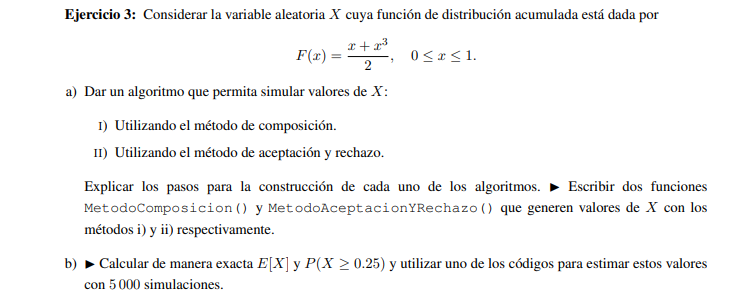

## Ejercicio 3

**Enunciado.** Considerar la variable aleatoria $X$ cuya función de distribución acumulada está dada por $F(x) = \dfrac{x + x^3}{2}$, $0 \le x \le 1$.

a) Dar un algoritmo que permita simular valores de $X$: I) utilizando el método de composición; II) utilizando el método de aceptación y rechazo. Explicar los pasos para la construcción de cada uno de los algoritmos. ▶ Escribir dos funciones `MetodoComposicion()` y `MetodoAceptacionYRechazo()` que generen valores de $X$ con los métodos i) y ii) respectivamente.  
b) ▶ Calcular de manera exacta $E[X]$ y $P(X \ge 0.25)$ y utilizar uno de los códigos para estimar estos valores con 5 000 simulaciones.

**a) I) Composición.** $F(x) = \tfrac12 F_1(x) + \tfrac12 F_2(x)$ con $F_1(x) = x$ (uniforme) y $F_2(x) = x^3$. Con probabilidad 1/2 se genera de $F_1$: $X = V$; si no, de $F_2$ por transformada inversa: $X = V^{1/3}$, con $V \sim U(0,1)$.

**a) II) Aceptación y rechazo.** $f(x) = F'(x) = \dfrac{1 + 3x^2}{2}$ en $[0,1]$. Con $Y \sim U(0,1)$ ($g = 1$), $c = \max f/g = f(1) = 2$. Se genera $Y$ y $U$, y se acepta $X = Y$ si $U < \dfrac{f(Y)}{c\,g(Y)} = \dfrac{1 + 3Y^2}{4}$.

**b) Valores exactos.**
$E[X] = \int_0^1 x\,\frac{1+3x^2}{2}\,dx = \frac12\left(\frac12 + \frac34\right) = \frac58 = 0.625$, $\quad P(X \ge 0.25) = 1 - F(0.25) = 1 - \frac{0.25 + 0.015625}{2} = 0.8671875$.

In [4]:
def MetodoComposicion():
    if random() < 0.5:
        return random()               # F1(x) = x
    return random() ** (1 / 3)        # F2(x) = x^3  ->  X = V^(1/3)


def MetodoAceptacionYRechazo():
    while True:
        Y = random()
        U = random()
        if U < (1 + 3 * Y**2) / 4:    # f(Y) / (c g(Y)), c = 2
            return Y


def ejercicio3(n_sim=5000):
    print("Ejercicio 3")
    print(f"Exactos: E[X] = {5 / 8}, P(X >= 0.25) = {1 - (0.25 + 0.25**3) / 2}")
    for nombre, metodo in [("Composición", MetodoComposicion),
                           ("Aceptación y rechazo", MetodoAceptacionYRechazo)]:
        valores = [metodo() for _ in range(n_sim)]
        esperanza = sum(valores) / n_sim
        prob = sum(1 for x in valores if x >= 0.25) / n_sim
        print(f"{nombre} ({n_sim} sim.): E[X] ≈ {esperanza:.5f}, P(X >= 0.25) ≈ {prob:.5f}")


ejercicio3()

Ejercicio 3
Exactos: E[X] = 0.625, P(X >= 0.25) = 0.8671875
Composición (5000 sim.): E[X] ≈ 0.62929, P(X >= 0.25) ≈ 0.87300
Aceptación y rechazo (5000 sim.): E[X] ≈ 0.62464, P(X >= 0.25) ≈ 0.86500


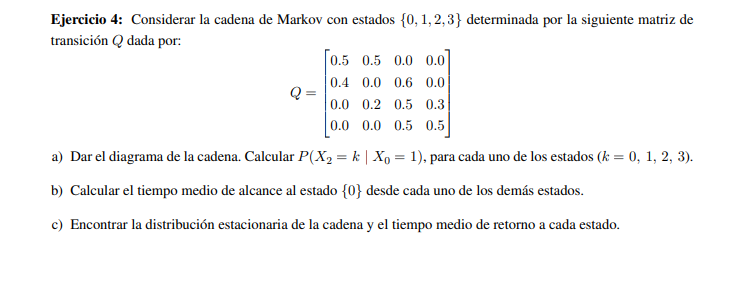

## Ejercicio 4

**Enunciado.** Considerar la cadena de Markov con estados $\{0, 1, 2, 3\}$ determinada por la matriz de transición

$$Q = \begin{pmatrix} 0.5 & 0.5 & 0 & 0 \\ 0.4 & 0 & 0.6 & 0 \\ 0 & 0.2 & 0.5 & 0.3 \\ 0 & 0 & 0.5 & 0.5 \end{pmatrix}$$

a) Dar el diagrama de la cadena. Calcular $P(X_2 = k \mid X_0 = 1)$ para cada uno de los estados ($k = 0, 1, 2, 3$).  
b) Calcular el tiempo medio de alcance al estado $\{0\}$ desde cada uno de los demás estados.  
c) Encontrar la distribución estacionaria de la cadena y el tiempo medio de retorno a cada estado.

**a) Diagrama** (arista $i \to j$ con probabilidad $Q_{ij}$):
$0 \circlearrowleft 0.5$, $0 \to 1$: 0.5; $1 \to 0$: 0.4, $1 \to 2$: 0.6; $2 \to 1$: 0.2, $2 \circlearrowleft 0.5$, $2 \to 3$: 0.3; $3 \to 2$: 0.5, $3 \circlearrowleft 0.5$. Es irreducible y aperiódica (hay lazos).

$P(X_2 = k \mid X_0 = 1)$ es la fila 1 de $Q^2$.

**b)** Con $k_0 = 0$, para $i \ne 0$: $k_i = 1 + \sum_j Q_{ij} k_j$. Es un sistema lineal: $(I - Q_{\{1,2,3\}})\,k = \mathbf 1$.

**c)** $\pi Q = \pi$, $\sum \pi_i = 1$; el tiempo medio de retorno a $i$ es $1/\pi_i$.

In [5]:
Q = np.array([[0.5, 0.5, 0.0, 0.0],
              [0.4, 0.0, 0.6, 0.0],
              [0.0, 0.2, 0.5, 0.3],
              [0.0, 0.0, 0.5, 0.5]])


def ejercicio4():
    n = len(Q)

    # a) fila 1 de Q^2
    Q2 = Q @ Q

    # b) (I - Q restringida a {1,2,3}) k = 1
    otros = [1, 2, 3]
    k = np.linalg.solve(np.eye(3) - Q[np.ix_(otros, otros)], np.ones(3))

    # c) pi (Q - I) = 0 con sum(pi) = 1
    A = np.vstack([Q.T - np.eye(n), np.ones(n)])
    b = np.zeros(n + 1)
    b[-1] = 1
    pi = np.linalg.lstsq(A, b, rcond=None)[0]

    print("Ejercicio 4")
    print("a) P(X2 = k | X0 = 1):", ", ".join(f"k={j}: {p:.2f}" for j, p in enumerate(Q2[1])))
    print("b) Tiempo medio de alcance a {0}:", ", ".join(f"desde {i}: {t:.2f}" for i, t in zip(otros, k)))
    print("c) Distribución estacionaria:", ", ".join(f"pi{j} = {p:.4f}" for j, p in enumerate(pi)),
          "(= 4/33, 5/33, 15/33, 9/33)")
    print("   Tiempo medio de retorno:", ", ".join(f"estado {j}: {1 / p:.4f}" for j, p in enumerate(pi)))


ejercicio4()

Ejercicio 4
a) P(X2 = k | X0 = 1): k=0: 0.20, k=1: 0.32, k=2: 0.30, k=3: 0.18
b) Tiempo medio de alcance a {0}: desde 1: 14.50, desde 2: 22.50, desde 3: 24.50
c) Distribución estacionaria: pi0 = 0.1212, pi1 = 0.1515, pi2 = 0.4545, pi3 = 0.2727 (= 4/33, 5/33, 15/33, 9/33)
   Tiempo medio de retorno: estado 0: 8.2500, estado 1: 6.6000, estado 2: 2.2000, estado 3: 3.6667
